# **PROJET DE ML ASSURANCE PREDICTION D'APPETENCE**

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier 
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [4]:
# Chargement des données
assu_data = pd.read_csv('train.csv')

In [8]:
#Structure du dataset
print(assu_data.shape)
print(assu_data.columns.tolist())

(381109, 12)
['id', 'Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']


In [6]:
assu_data.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [10]:
#verifications des valeurs manquantes et doublons
print(assu_data.isnull().sum())
print(assu_data.duplicated().sum())

id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64
0


In [11]:
#==============================================================
# Analyse Exploratoire des données
#==============================================================

In [13]:
# Verifications d'un eventuel desequilibre du target y (Response)
target_des = assu_data["Response"].value_counts(normalize = True)*100
print(target_des.round(2))

Response
0    87.74
1    12.26
Name: proportion, dtype: float64


In [ ]:
#Soit 12.26 % de notre cible et 87.74% des nons interésées.

In [15]:
#statistiques descriptives des variables numeriques
assu_data.describe()

,id,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,190555.000000,38.822584,0.997869,26.388807,0.458210,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,15.511611,0.046110,13.229888,0.498251,17213.155057,54.203995,83.671304,0.327936
min,1.000000,20.000000,0.000000,0.000000,0.000000,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,25.000000,1.000000,15.000000,0.000000,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,36.000000,1.000000,28.000000,0.000000,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,49.000000,1.000000,35.000000,1.000000,39400.000000,152.000000,227.000000,0.000000
max,381109.000000,85.000000,1.000000,52.000000,1.000000,540165.000000,163.000000,299.000000,1.000000


In [19]:
# Taux de souscription selon la cible y (Response = 1) suivants les facteurs clés
print("\n Taux de souscription selon les personnes deja assurées")
print((assu_data.groupby("Previously_Insured")["Response"].mean() * 100).round(2))
print("\n Taux de souscription selon les accidents")
print((assu_data.groupby('Vehicle_Damage')['Response'].mean() * 100).round(2))
print("\n Taux de souscription selon l'âge des vehicules")
print((assu_data.groupby('Vehicle_Age')['Response'].mean() * 100).round(2))


 Taux de souscription selon les personnes deja assurées
Previously_Insured
0    22.55
1     0.09
Name: Response, dtype: float64

 Taux de souscription selon les accidents
Vehicle_Damage
No      0.52
Yes    23.77
Name: Response, dtype: float64

 Taux de souscription selon l'âge des vehicules
Vehicle_Age
1-2 Year     17.38
< 1 Year      4.37
> 2 Years    29.37
Name: Response, dtype: float64


C:\Users\GIVMMBD\AppData\Local\Temp\ipykernel_2920\472400986.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=assu_data, x='Response', ax=axes[0], palette='viridis')
C:\Users\GIVMMBD\AppData\Local\Temp\ipykernel_2920\472400986.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=assu_data, x='Previously_Insured', y='Response', ax=axes[1], palette='Set2')
C:\Users\GIVMMBD\AppData\Local\Temp\ipykernel_2920\472400986.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=assu_data, x='Vehicle_Damage', y='Response', ax=axes[2], 

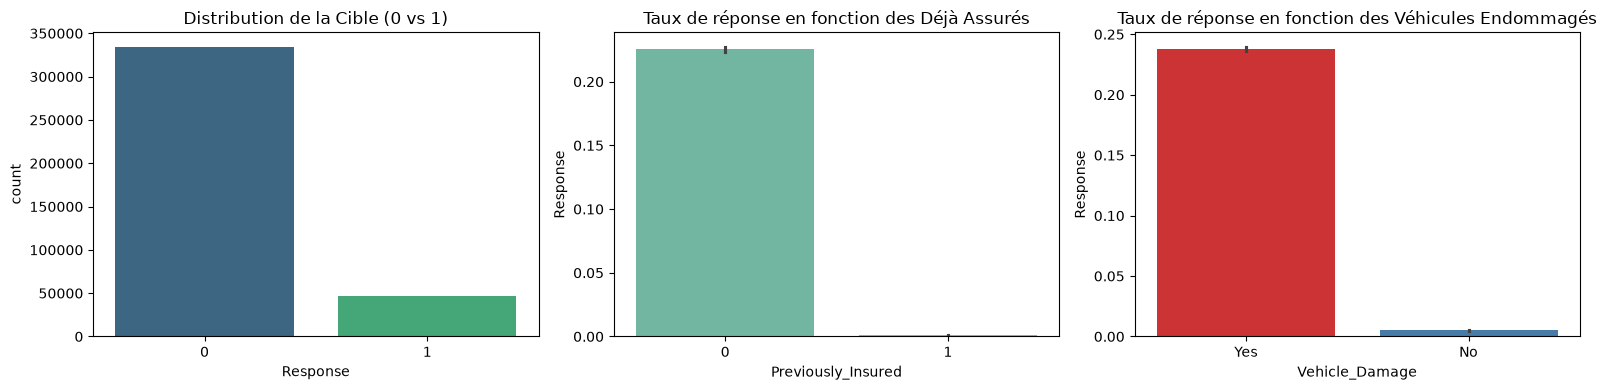

In [21]:
# 4. Visualisation de la situation de la variable cible y 
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=assu_data, x='Response', ax=axes[0], palette='viridis')
axes[0].set_title('Distribution de la Cible (0 vs 1)')

sns.barplot(data=assu_data, x='Previously_Insured', y='Response', ax=axes[1], palette='Set2')
axes[1].set_title('Taux de réponse en fonction des Déjà Assurés')

sns.barplot(data=assu_data, x='Vehicle_Damage', y='Response', ax=axes[2], palette='Set1')
axes[2].set_title('Taux de réponse en fonction des Véhicules Endommagés')

plt.tight_layout()
plt.show()

In [32]:
#Creation des nouvelles varibles 
assu = assu_data.drop(columns=["id"]).copy()
assu['Prime_par_jour'] = assu['Annual_Premium'] / (assu['Vintage'] + 1)
assu['Categorie_Age'] = pd.cut(
    assu['Age'], 
    bins=[17, 25, 45, 60, 100], 
    labels=['Jeune', 'Actif', 'Senior', 'Retraite']
)

In [38]:
# Séparation des données et Découpage APPRENTISSAGE(a) / EVALUATION(eval)
X = assu.drop(columns=['Response'])
y = assu['Response']

X_a, X_eval, y_a, y_eval = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"données d'apprentissage : {X_a.shape} | données d'évaluation : {X_eval.shape}")

données d'apprentissage : (304887, 12) | données d'évaluation : (76222, 12)


In [42]:
# Le Prétraitement Automatisé
num_cols = ['Age', 'Annual_Premium', 'Vintage', 'Prime_par_jour']
cat_cols = ['Gender', 'Driving_License', 'Region_Code', 'Previously_Insured', 
            'Vehicle_Age', 'Vehicle_Damage', 'Policy_Sales_Channel', 'Categorie_Age']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)
print("Preprocesseur configuré avec succès !")

Preprocesseur configuré avec succès !


In [46]:
#Entraînement en boucle avec trois 3 algo
ratio_desequilibre = (y_a == 0).sum() / (y_a == 1).sum()

modeles = {
    "Régression Logistique (Baseline)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, scale_pos_weight=ratio_desequilibre, n_jobs=-1, random_state=42, eval_metric='logloss')
}

# Initialisations des espaces de stockage du modèle
resultats = []
pipelines_entraines = {}

for nom, clf in modeles.items():
    print(f"Entraînement en cours : {nom}...")
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_a, y_a)
    pipelines_entraines[nom] = pipe
    
    y_predict = pipe.predict(X_eval)
    y_proba = pipe.predict_proba(X_eval)[:, 1]
    
    auc = roc_auc_score(y_eval, y_proba)
    report = classification_report(y_eval, y_predict, output_dict=True)
    
    resultats.append({
        "Modèle": nom,
        "ROC-AUC": round(auc, 4),
        "Recall (Classe 1)": round(report['1']['recall'], 4),
        "Precision (Classe 1)": round(report['1']['precision'], 4),
        "F1-Score (Classe 1)": round(report['1']['f1-score'], 4)
    })
df_resultats = pd.DataFrame(resultats).sort_values(by="ROC-AUC", ascending=False)
print("\n--- TABLEAU COMPARATIF DES PERFORMANCES ---")
display(df_resultats)

Entraînement en cours : Régression Logistique (Baseline)...
Entraînement en cours : Random Forest...
Entraînement en cours : XGBoost...

--- TABLEAU COMPARATIF DES PERFORMANCES ---


,Modèle,ROC-AUC,Recall (Classe 1),Precision (Classe 1),F1-Score (Classe 1)
2,XGBoost,0.8571,0.9168,0.2866,0.4367
0,Régression Logistique (Baseline),0.8536,0.9244,0.2830,0.4334
1,Random Forest,0.8536,0.9269,0.2793,0.4292


In [48]:
from sklearn.metrics import confusion_matrix, precision_recall_curve, classification_report

In [51]:
# 1. Récupération du meilleur pipeline (XGBoost)
meilleur_pipe = pipelines_entraines["XGBoost"]
y_proba_xgb = meilleur_pipe.predict_proba(X_eval)[:, 1]

In [52]:
# 2. Recherche du seuil optimal (maximisation du F1-Score)
precisions, recalls, thresholds = precision_recall_curve(y_eval, y_proba_xgb)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Seuil optimal trouvé : {best_threshold:.4f} (vs 0.5000 par défaut)")
print(f"F1-Score maximal atteint : {f1_scores[best_idx]:.4f}")

Seuil optimal trouvé : 0.6488 (vs 0.5000 par défaut)
F1-Score maximal atteint : 0.4581


In [53]:
# 3. Comparaison Avant / Après optimisation du seuil
y_pred_optim = (y_proba_xgb >= best_threshold).astype(int)
print("\n--- RAPPORT DE CLASSIFICATION AVEC SEUIL OPTIMAL ---")
print(classification_report(y_eval, y_pred_optim))


--- RAPPORT DE CLASSIFICATION AVEC SEUIL OPTIMAL ---
              precision    recall  f1-score   support

           0       0.96      0.77      0.85     66880
           1       0.32      0.79      0.46      9342

    accuracy                           0.77     76222
   macro avg       0.64      0.78      0.66     76222
weighted avg       0.88      0.77      0.81     76222



In [56]:
# 4. Extraction de l'importance des variables (Feature Importance)
preproc = meilleur_pipe.named_steps['preprocessor']
xgb_model = meilleur_pipe.named_steps['classifier']


In [57]:
# Récupération des noms de colonnes après OneHotEncoder
cat_feature_names = preproc.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = np.concatenate([num_cols, cat_feature_names])

importances = pd.Series(xgb_model.feature_importances_, index=all_feature_names)
top_10 = importances.sort_values(ascending=False).head(10)

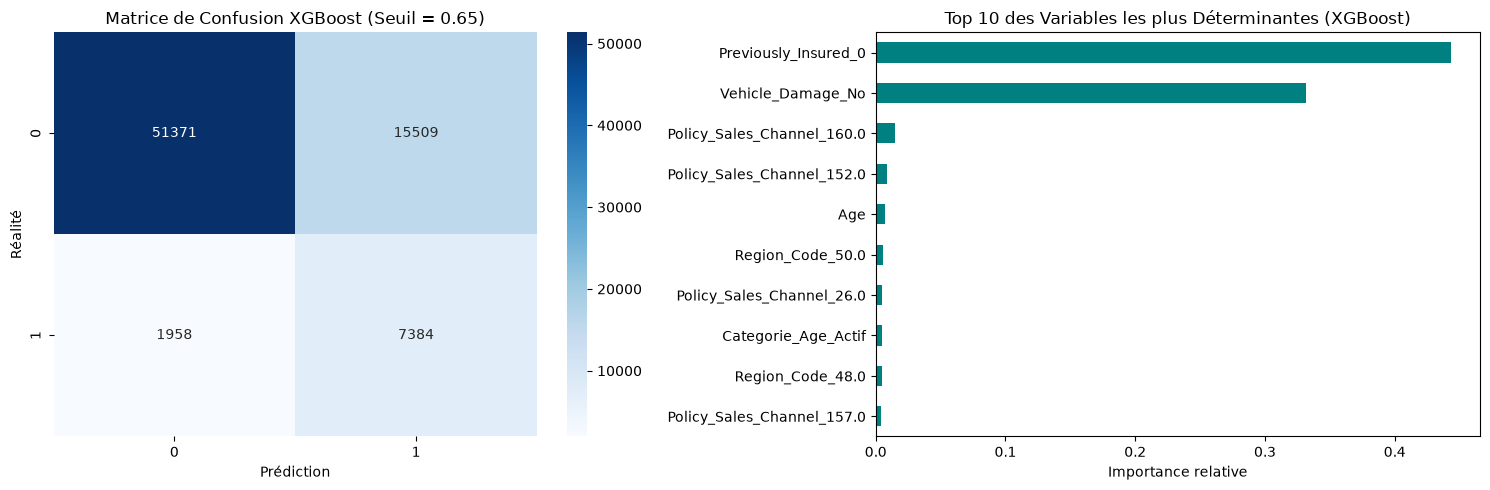

In [58]:
# 5. Visualisations (Matrice de Confusion + Top 10 Variables)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cm = confusion_matrix(y_eval, y_pred_optim)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Matrice de Confusion XGBoost (Seuil = {best_threshold:.2f})')
axes[0].set_xlabel('Prédiction')
axes[0].set_ylabel('Réalité')

top_10.sort_values().plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title('Top 10 des Variables les plus Déterminantes (XGBoost)')
axes[1].set_xlabel('Importance relative')

plt.tight_layout()
plt.show()


In [59]:
#Sauvegarde du Pipeline & Simulation en Production
import joblib

In [60]:
# 1. Sauvegarde du pipeline complet (Prétraitement + XGBoost) et du seuil optimal
artefact_production = {
    "pipeline": pipelines_entraines["XGBoost"],
    "seuil_optimal": best_threshold
}
joblib.dump(artefact_production, "modele_cross_sell_assurance.joblib")
print("Modèle sauvegardé avec succès sous 'modele_cross_sell_assurance.joblib' !")

# 2. Fonction de prédiction sur un nouveau client
def scorer_client(donnees_client_dict, fichier_modele="modele_cross_sell_assurance.joblib"):
    modele_charge = joblib.load(fichier_modele)
    pipe = modele_charge["pipeline"]
    seuil = modele_charge["seuil_optimal"]
    
    df_new = pd.DataFrame([donnees_client_dict])
    
    # Application du même Feature Engineering que lors de l'entraînement
    df_new['Prime_par_jour'] = df_new['Annual_Premium'] / (df_new['Vintage'] + 1)
    df_new['Categorie_Age'] = pd.cut(
        df_new['Age'],
        bins=[17, 25, 45, 60, 100],
        labels=['Jeune', 'Actif', 'Senior', 'Retraite']
    )
    
    proba = pipe.predict_proba(df_new)[:, 1][0]
    decision = int(proba >= seuil)
    
    return {
        "Probabilité_Souscription": f"{proba * 100:.2f} %",
        "Appeler_Client": "OUI (Prioritaire)" if decision == 1 else "NON"
    }

# 3. Test sur un profil client type
nouveau_client = {
    "Gender": "Male",
    "Age": 38,
    "Driving_License": 1,
    "Region_Code": 28.0,
    "Previously_Insured": 0,
    "Vehicle_Age": "1-2 Year",
    "Vehicle_Damage": "Yes",
    "Annual_Premium": 35000.0,
    "Policy_Sales_Channel": 26.0,
    "Vintage": 150
}

print("\nRésultat du scoring en direct :")
print(scorer_client(nouveau_client))

Modèle sauvegardé avec succès sous 'modele_cross_sell_assurance.joblib' !

Résultat du scoring en direct :
{'Probabilité_Souscription': '81.35 %', 'Appeler_Client': 'OUI (Prioritaire)'}
